# Detección de fraude en transacciones con tarjeta de crédito – Entrega final

Diplomado en Ciencia de Datos y Análisis Avanzado – Proyecto Final Integrador (Grupo 8).

Este notebook produce **todas** las cifras, tablas y figuras del informe final (`informe-final.md`). Las salidas se guardan en `results/`. Sigue CRISP-DM:

1. Comprensión de los datos y calidad
2. EDA e hipótesis (H1–H4)
3. Drift entre train y test
4. Preparación: variables sin fuga de información
5. Modelado: validación temporal, baselines, modelos y regla de selección ex ante
6. Umbral por costo
7. Evaluación final sobre test (una sola vez)
8. Impacto temporal, interpretación, impacto en el negocio y auditoría por grupos

Reglas del trabajo: `SEED = 42`; el test no interviene en la selección ni en el ajuste de escaladores, codificadores o umbrales; los diagnósticos posteriores se identifican como tales; los datos son sintéticos, por lo que no se presentan resultados como representativos de producción.

In [1]:
import zipfile, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
T0 = time.time()

SEED = 42
np.random.seed(SEED)
DATA_DIR, RES = Path('dataset'), Path('results')
RES.mkdir(exist_ok=True)

# Paso previo: extraer dataset.zip en dataset/ si los CSV todavía no existen
if not all((DATA_DIR / f).exists() for f in ['fraudTrain.csv', 'fraudTest.csv']):
    DATA_DIR.mkdir(exist_ok=True)
    with zipfile.ZipFile('dataset.zip') as z:
        z.extractall(DATA_DIR)
    print('Extraído en', DATA_DIR)

# Estilo de gráficos (paleta categórica validada: azul, naranja, aqua)
BLUE, ORANGE, AQUA, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
    'axes.edgecolor': MUTED, 'text.color': INK, 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10, 'axes.titlesize': 11,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

def save(name):
    plt.tight_layout()
    plt.savefig(RES / name, dpi=150)
    plt.show()

tr = pd.read_csv(DATA_DIR / 'fraudTrain.csv', index_col=0, parse_dates=['trans_date_trans_time'])
te = pd.read_csv(DATA_DIR / 'fraudTest.csv', index_col=0, parse_dates=['trans_date_trans_time'])
tr['split'], te['split'] = 'train', 'test'
raw = pd.concat([tr, te], ignore_index=True)
DAYS_TEST = (te.trans_date_trans_time.max() - te.trans_date_trans_time.min()).total_seconds() / 86400
print(tr.shape, te.shape, f'| días de test: {DAYS_TEST:.0f}')

(1296675, 23) (555719, 23) | días de test: 193


## 1. Comprensión de los datos y calidad

Dataset *Credit Card Transactions Fraud Detection* (Kaggle, simulador Sparkov). Se mantiene el corte cronológico original: se entrena con `fraudTrain.csv` y se evalúa con `fraudTest.csv`.

In [2]:
def calidad(df):
    q1, q3 = df.amt.quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
    return {
        'filas': len(df), 'fraudes': int(df.is_fraud.sum()), 'tasa_fraude_pct': round(df.is_fraud.mean() * 100, 3),
        'desde': str(df.trans_date_trans_time.min()), 'hasta': str(df.trans_date_trans_time.max()),
        'nulos': int(df.isna().sum().sum()), 'filas_duplicadas': int(df.duplicated().sum()),
        'trans_num_repetidos': int(df.trans_num.duplicated().sum()),
        'tarjetas': df.cc_num.nunique(), 'comercios': df.merchant.nunique(),
        'categorias': df.category.nunique(), 'ocupaciones': df.job.nunique(),
        'amt_mediana': round(df.amt.median(), 2), 'amt_media': round(df.amt.mean(), 2), 'amt_max': df.amt.max(),
        'amt_pct_sobre_limite_IQR': round((df.amt > lim).mean() * 100, 2),
        'monto_fraude_total_usd': round(df.loc[df.is_fraud == 1, 'amt'].sum(), 2)}
cal = pd.DataFrame({'train': calidad(tr), 'test': calidad(te)})
cal.to_csv(RES / 'eda_calidad.csv')
display(cal)

print('Máximo monto de fraude (train):', tr.loc[tr.is_fraud == 1, 'amt'].max())
print('\nLas 50 transacciones de mayor monto (train), por categoría y clase:')
print(tr.nlargest(50, 'amt').groupby(['category', 'is_fraud']).size())
print('\nTarjetas de test que también están en train:', round(te.cc_num.isin(tr.cc_num).mean() * 100, 1), '%')

,train,test
filas,1296675,555719
fraudes,7506,2145
tasa_fraude_pct,0.579,0.386
desde,2019-01-01 00:00:18,2020-06-21 12:14:25
hasta,2020-06-21 12:13:37,2020-12-31 23:59:34
nulos,0,0
filas_duplicadas,0,0
trans_num_repetidos,0,0
tarjetas,983,924
comercios,693,693


Máximo monto de fraude (train): 1376.04

Las 50 transacciones de mayor monto (train), por categoría y clase:
category      is_fraud
shopping_net  0            1
shopping_pos  0            1
travel        0           48
dtype: int64

Tarjetas de test que también están en train: 100.0 %


**Lectura.** No hay nulos ni duplicados. Los montos más altos del train son compras legítimas de la categoría `travel` (no son errores ni fraude), por lo que se conservan y se usa `log1p(amt)` para domar la asimetría (cierra la decisión pendiente de la pre-entrega: transformación log en lugar de winsorizing, porque el valor extremo no es un dato erróneo).

## 2. EDA e hipótesis

- **H1.** El fraude se concentra en franjas horarias nocturnas (22–03 h).
- **H2.** El fraude se concentra en ciertas categorías de comercio (compras online y `grocery_pos`).
- **H3.** Los montos fraudulentos son mayores que los legítimos.
- **H4.** El comportamiento histórico de cada tarjeta (desvío respecto de su patrón) aporta señal adicional; se contrasta en la sección de ablaciones.

In [3]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

e = tr[['trans_date_trans_time', 'category', 'amt', 'lat', 'long', 'merch_lat', 'merch_long', 'is_fraud']].copy()
e['hour'] = e.trans_date_trans_time.dt.hour
e['dist_km'] = haversine(e.lat, e.long, e.merch_lat, e.merch_long)
base = e.is_fraud.mean()

# H1: hora
h1 = e.groupby('hour').is_fraud.agg(tasa='mean', fraudes='sum', n='count')
noche = e.hour.isin([22, 23, 0, 1, 2, 3])
h1_res = pd.Series({'tasa_noche_22_03': e[noche].is_fraud.mean(), 'tasa_resto_dia': e[~noche].is_fraud.mean(),
                    'pct_fraudes_en_noche': e[noche].is_fraud.sum() / e.is_fraud.sum(),
                    'pct_transacciones_en_noche': noche.mean()})
h1.to_csv(RES / 'eda_h1_hora.csv'); h1_res.to_csv(RES / 'eda_h1_resumen.csv', header=['valor'])
# H2: categoría
h2 = e.groupby('category').is_fraud.agg(tasa='mean', fraudes='sum', n='count').sort_values('tasa', ascending=False)
h2.to_csv(RES / 'eda_h2_categoria.csv')
# H3: monto
h3 = e.groupby('is_fraud').amt.describe()
bins = [0, 10, 50, 100, 200, 300, 500, 1000, np.inf]
h3b = e.groupby(pd.cut(e.amt, bins)).is_fraud.agg(tasa='mean', fraudes='sum', n='count')
h3.to_csv(RES / 'eda_h3_monto.csv'); h3b.to_csv(RES / 'eda_h3_tramos.csv')
# Distancia
h4d = e.groupby('is_fraud').dist_km.describe()
h4d.to_csv(RES / 'eda_distancia.csv')
display(h1_res.round(4).to_frame('valor')); display(h2.round(4)); display(h3.round(1)); display(h3b.round(4)); display(h4d.round(1))

,valor
tasa_noche_22_03,0.0209
tasa_resto_dia,0.0012
pct_fraudes_en_noche,0.8476
pct_transacciones_en_noche,0.2351


,tasa,fraudes,n
category,,,
shopping_net,0.0176,1713,97543
misc_net,0.0145,915,63287
grocery_pos,0.0141,1743,123638
shopping_pos,0.0072,843,116672
gas_transport,0.0047,618,131659
misc_pos,0.0031,250,79655
grocery_net,0.0029,134,45452
travel,0.0029,116,40507
entertainment,0.0025,233,94014


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.7,154.0,1.0,9.6,47.3,82.5,28948.9
1,7506.0,531.3,390.6,1.1,245.7,396.5,900.9,1376.0


,tasa,fraudes,n
amt,,,
"(0.0, 10.0]",0.0016,525,335929
"(10.0, 50.0]",0.0032,1082,336370
"(50.0, 100.0]",0.0001,45,389483
"(100.0, 200.0]",0.0009,150,172969
"(200.0, 300.0]",0.0252,796,31626
"(300.0, 500.0]",0.0859,1260,14667
"(500.0, 1000.0]",0.2308,2699,11695
"(1000.0, inf]",0.2411,949,3936


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,76.1,29.1,0.0,55.3,78.2,98.5,152.1
1,7506.0,76.3,28.8,0.7,55.6,77.9,98.4,144.5


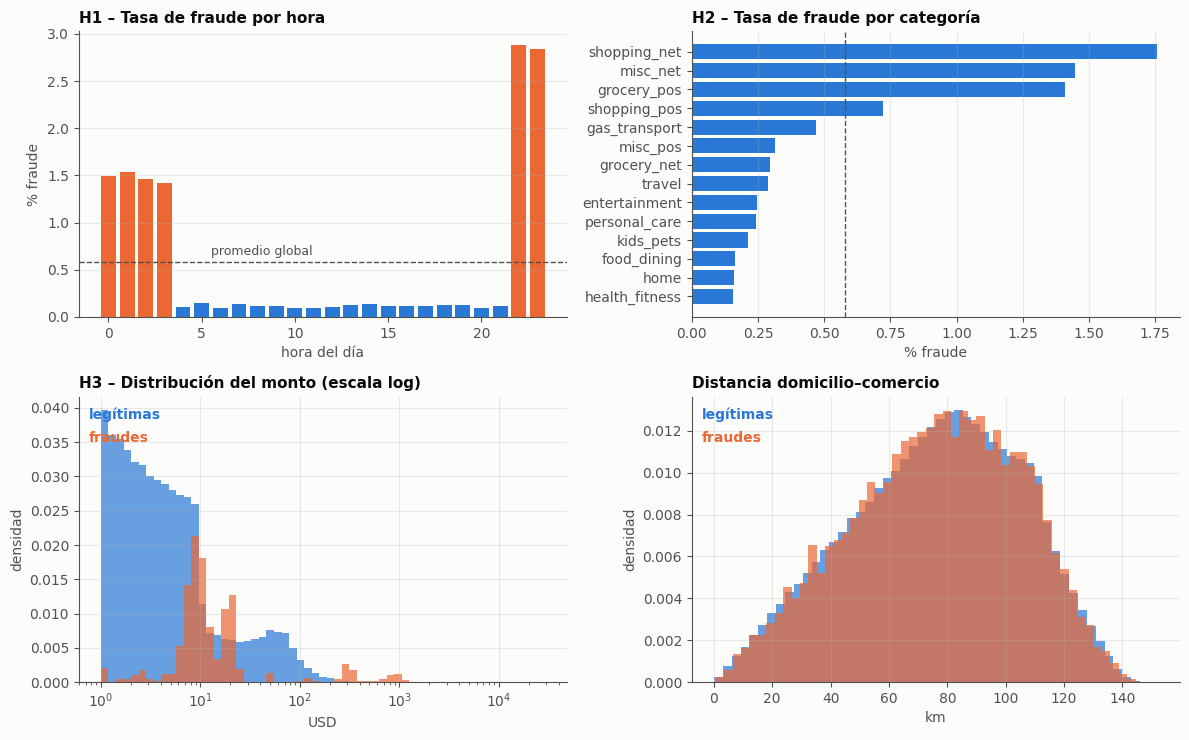

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
a = ax[0, 0]; a.bar(h1.index, h1.tasa * 100, color=[ORANGE if h in (22, 23, 0, 1, 2, 3) else BLUE for h in h1.index])
a.axhline(base * 100, color=MUTED, lw=1, ls='--'); a.text(5.5, base * 100 + .08, 'promedio global', color=MUTED, fontsize=9)
a.set(title='H1 – Tasa de fraude por hora', xlabel='hora del día', ylabel='% fraude'); a.grid(axis='x', visible=False)
a = ax[0, 1]; d2 = h2.sort_values('tasa'); a.barh(d2.index, d2.tasa * 100, color=BLUE)
a.axvline(base * 100, color=MUTED, lw=1, ls='--'); a.set(title='H2 – Tasa de fraude por categoría', xlabel='% fraude'); a.grid(axis='y', visible=False)
a = ax[1, 0]; lb = np.linspace(0, np.log10(e.amt.max()), 60)
a.hist(e.loc[e.is_fraud == 0, 'amt'], bins=10 ** lb, color=BLUE, alpha=.7, density=True)
a.hist(e.loc[e.is_fraud == 1, 'amt'], bins=10 ** lb, color=ORANGE, alpha=.7, density=True)
a.set_xscale('log'); a.set(title='H3 – Distribución del monto (escala log)', xlabel='USD', ylabel='densidad')
a.text(.02, .92, 'legítimas', color=BLUE, transform=a.transAxes, fontweight='bold'); a.text(.02, .84, 'fraudes', color=ORANGE, transform=a.transAxes, fontweight='bold')
a = ax[1, 1]; a.hist(e.loc[e.is_fraud == 0, 'dist_km'], bins=50, color=BLUE, alpha=.7, density=True)
a.hist(e.loc[e.is_fraud == 1, 'dist_km'], bins=50, color=ORANGE, alpha=.7, density=True)
a.set(title='Distancia domicilio–comercio', xlabel='km', ylabel='densidad')
a.text(.02, .92, 'legítimas', color=BLUE, transform=a.transAxes, fontweight='bold'); a.text(.02, .84, 'fraudes', color=ORANGE, transform=a.transAxes, fontweight='bold')
save('fig_eda.png')

**Lectura.** (H1) el fraude se concentra de noche; (H2) las compras online (`shopping_net`, `misc_net`) y `grocery_pos` tienen tasas varias veces mayores que el promedio; (H3) los montos fraudulentos son mayores en promedio, pero su distribución es **bimodal**: hay fraudes de monto chico (hasta ≈ 50 USD) y fraudes de monto alto, mientras que casi no hay fraude entre 50 y 200 USD (tasa < 0,1 %) y la tasa supera el 2,5 % desde 200 USD (≈ 24 % por encima de 1.000 USD); es un patrón muy regular, típico del simulador; la distancia domicilio–comercio casi no discrimina por sí sola (la distribución es prácticamente idéntica entre clases). H4 se evalúa con ablaciones en la sección 8.

## 3. Drift entre train y test

Devolución del tutor: *revisar el cambio de tasa de fraude entre train y test, porque puede indicar drift.* Se estudia (a) la serie mensual, (b) la tasa por categoría en cada período, (c) cuánto del cambio se explica por la mezcla de transacciones (composición) y (d) el PSI de las variables principales (regla práctica: < 0,1 estable; 0,1–0,25 moderado; > 0,25 fuerte).

In [5]:
raw['mes'] = raw.trans_date_trans_time.dt.to_period('M').dt.to_timestamp()
mes = raw.groupby(['mes', 'split']).is_fraud.agg(tasa='mean', fraudes='sum', n='count').reset_index()
mes.to_csv(RES / 'drift_mensual.csv', index=False)

cat_tr = tr.groupby('category').is_fraud.mean(); cat_te = te.groupby('category').is_fraud.mean()
mix_tr = tr.category.value_counts(normalize=True); mix_te = te.category.value_counts(normalize=True)
dcat = pd.DataFrame({'tasa_train': cat_tr, 'tasa_test': cat_te, 'mezcla_train': mix_tr, 'mezcla_test': mix_te})
dcat.to_csv(RES / 'drift_categoria.csv')

# Descomposición: tasa que se esperaría en test si cada categoría mantuviera su tasa de train
esperada_por_mezcla = float((mix_te * cat_tr).sum())
descomp = pd.Series({'tasa_train': tr.is_fraud.mean(), 'tasa_test': te.is_fraud.mean(),
                     'tasa_test_esperada_con_tasas_train_y_mezcla_test': esperada_por_mezcla})
descomp.to_csv(RES / 'drift_descomposicion.csv', header=['valor'])

def psi(a, b, bins=10):
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    pa = np.clip(np.histogram(a, edges)[0] / len(a), 1e-6, None); pb = np.clip(np.histogram(b, edges)[0] / len(b), 1e-6, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))
def psi_cat(a, b):
    pa, pb = a.value_counts(normalize=True), b.value_counts(normalize=True)
    pa, pb = pa.align(pb, fill_value=1e-6); pa, pb = pa.clip(1e-6), pb.clip(1e-6)
    return float(((pb - pa) * np.log(pb / pa)).sum())

dtr_, dte_ = tr.copy(), te.copy()
for d_ in (dtr_, dte_):
    d_['hour'] = d_.trans_date_trans_time.dt.hour
    d_['dist_km'] = haversine(d_.lat, d_.long, d_.merch_lat, d_.merch_long)
    d_['age'] = (d_.trans_date_trans_time - pd.to_datetime(d_.dob)).dt.days / 365.25
psi_tab = pd.Series({'amt': psi(dtr_.amt, dte_.amt), 'dist_km': psi(dtr_.dist_km, dte_.dist_km), 'hour': psi(dtr_.hour, dte_.hour),
                     'age': psi(dtr_.age, dte_.age), 'city_pop': psi(dtr_.city_pop, dte_.city_pop),
                     'category': psi_cat(dtr_.category, dte_.category)}, name='PSI')
psi_tab.to_csv(RES / 'drift_psi.csv', header=True)
display(descomp.round(5).to_frame('valor')); display(psi_tab.round(4).to_frame()); display(dcat.round(4))

# Fraude por tarjeta y por mes dentro del test: ¿cambia la intensidad por tarjeta activa?
print('Fraudes/mes (train) vs (test):')
print(mes.groupby('split').agg(fraudes_mes=('fraudes', 'mean'), tx_mes=('n', 'mean')).round(0))

,valor
tasa_train,0.00579
tasa_test,0.00386
tasa_test_esperada_con_tasas_train_y_mezcla_test,0.00578


,PSI
amt,0.0001
dist_km,0.0000
hour,0.0000
age,0.0077
city_pop,0.0000
category,0.0000


,tasa_train,tasa_test,mezcla_train,mezcla_test
category,,,,
entertainment,0.0025,0.0015,0.0725,0.0722
food_dining,0.0017,0.0014,0.0705,0.0707
gas_transport,0.0047,0.0027,0.1015,0.1014
grocery_net,0.0029,0.0021,0.0351,0.0350
grocery_pos,0.0141,0.0092,0.0954,0.0946
health_fitness,0.0015,0.0014,0.0662,0.0660
home,0.0016,0.0013,0.0949,0.0942
kids_pets,0.0021,0.0013,0.0872,0.0876
misc_net,0.0145,0.0098,0.0488,0.0492


Fraudes/mes (train) vs (test):
       fraudes_mes   tx_mes
split                      
test         306.0  79388.0
train        417.0  72038.0


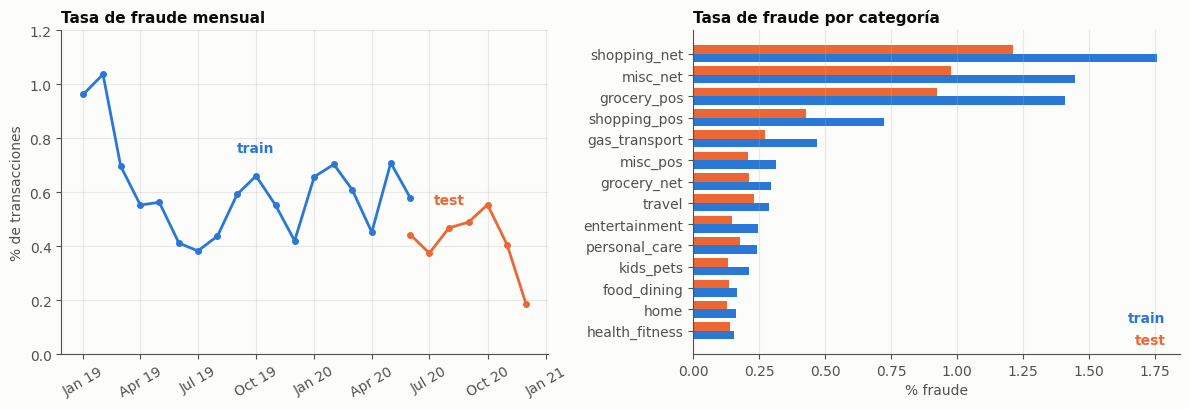

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
a = ax[0]
for sp, col in (('train', BLUE), ('test', ORANGE)):
    d_ = mes[mes.split == sp]; a.plot(d_.mes, d_.tasa * 100, color=col, lw=2, marker='o', ms=4)
    i_ = len(d_) // 2 if sp == 'train' else 2
    a.text(d_.mes.iloc[i_], d_.tasa.iloc[i_] * 100 + .09, sp, color=col, fontweight='bold', ha='center')
a.axhline(0, color=MUTED, lw=.6); a.set(title='Tasa de fraude mensual', ylabel='% de transacciones', ylim=(0, 1.2))
a.xaxis.set_major_formatter(mdates.DateFormatter('%b %y')); a.tick_params(axis='x', rotation=30)
a = ax[1]; dd = dcat.sort_values('tasa_train'); y = np.arange(len(dd))
a.barh(y - .2, dd.tasa_train * 100, .4, color=BLUE); a.barh(y + .2, dd.tasa_test * 100, .4, color=ORANGE)
a.set_yticks(y); a.set_yticklabels(dd.index); a.set(title='Tasa de fraude por categoría', xlabel='% fraude'); a.grid(axis='y', visible=False)
a.text(.97, .1, 'train', color=BLUE, transform=a.transAxes, ha='right', fontweight='bold'); a.text(.97, .03, 'test', color=ORANGE, transform=a.transAxes, ha='right', fontweight='bold')
save('fig_drift.png')

**Lectura.** La tasa cae de 0,58 % a 0,39 %. Si cada categoría conservara su tasa de train sobre la mezcla de test, la tasa esperada sería prácticamente la de train: **el cambio no se explica por la composición de categorías**, sino por una menor intensidad de fraude dentro de las categorías (cambio de régimen del simulador). Las distribuciones de las variables (PSI) son estables. Consecuencia para el modelo: el ranking puede mantenerse, pero la **precisión a un umbral fijo cae** cuando baja la prevalencia; se mide en la sección 8.

## 4. Preparación de datos: variables sin fuga de información

Devolución del tutor: *las variables históricas por tarjeta deben calcularse usando solo transacciones anteriores.* Se construyen con ventanas **estrictamente pasadas** (`cumcount`, sumas acumuladas restadas de la fila actual, `rolling(..., closed='left')`).

Para las primeras transacciones del test se usa el historial real de esa tarjeta en el train (es pasado, no futuro). Ninguna etiqueta (`is_fraud`) pasada se usa como variable (en producción las etiquetas llegan con demora).

Se excluyen datos personales o identificadores: `first`, `last`, `street`, `trans_num`, `cc_num`, `unix_time`, `zip`, `city`, `state` y coordenadas crudas.

In [7]:
def build_features(df):
    d = df.sort_values(['cc_num', 'trans_date_trans_time'], kind='mergesort').reset_index(drop=True)
    t = d.trans_date_trans_time
    d['hour'], d['dow'] = t.dt.hour, t.dt.dayofweek
    d['is_night'] = ((d.hour >= 22) | (d.hour <= 3)).astype(int)
    d['age'] = (t - pd.to_datetime(d.dob)).dt.days / 365.25
    d['dist_km'] = haversine(d.lat, d.long, d.merch_lat, d.merch_long)
    d['log_amt'], d['log_city_pop'] = np.log1p(d.amt), np.log1p(d.city_pop)
    d['gender_M'] = (d.gender == 'M').astype(int)

    g = d.groupby('cc_num')
    n_prev = g.cumcount()                                   # transacciones previas de la tarjeta
    d['n_prev'] = n_prev
    d['secs_since_prev'] = (t - g.trans_date_trans_time.shift(1)).dt.total_seconds()
    d['log_secs_since_prev'] = np.log1p(d.secs_since_prev).fillna(np.log1p(30 * 86400))
    # estadísticas pasadas del monto: acumulado menos la fila actual
    s1 = g.amt.cumsum() - d.amt
    s2 = (d.amt ** 2).groupby(d.cc_num).cumsum() - d.amt ** 2
    n = n_prev.replace(0, np.nan)
    mean = s1 / n
    d['past_mean_amt'] = mean.fillna(d.amt)
    d['past_std_amt'] = np.sqrt((s2 / n - mean ** 2).clip(lower=0)).fillna(0)
    d['amt_ratio'] = (d.amt / mean).fillna(1)
    d['amt_z'] = ((d.amt - mean) / (d.past_std_amt + 1)).fillna(0)
    # ventanas temporales estrictamente pasadas (excluyen la transacción actual)
    tmp = d[['cc_num', 'trans_date_trans_time', 'amt']]
    for w in ('1h', '24h'):
        r = tmp.groupby('cc_num').rolling(w, on='trans_date_trans_time', closed='left').amt
        rc_, rs_ = r.count(), r.sum()
        # el resultado viene ordenado por (tarjeta, tiempo), igual que d: se alinea por posición
        assert (rc_.index.get_level_values(0).values == d.cc_num.values).all()
        d[f'cnt_{w}'] = np.nan_to_num(rc_.values)
        d[f'sum_{w}'] = np.nan_to_num(rs_.values)
        d[f'log_sum_{w}'] = np.log1p(d[f'sum_{w}'])
    d['new_cat'] = (d.groupby(['cc_num', 'category']).cumcount() == 0).astype(int)
    return d

t0 = time.time()
F = build_features(raw)
print(F.shape, f'{time.time() - t0:.0f} s')

(1852394, 46) 2 s


**Prueba anti-fuga.** Si las variables usan solo pasado, calcularlas con los datos truncados en una fecha de corte debe dar *exactamente* los mismos valores que calcularlas con todos los datos. Como control positivo, una variable deliberadamente "con futuro" (media del monto por tarjeta sobre todo el período) **sí** debe cambiar.

In [8]:
CUT = pd.Timestamp('2019-09-01')
F_sub = build_features(raw[raw.trans_date_trans_time < CUT])
HIST_RAW = ['n_prev', 'secs_since_prev', 'past_mean_amt', 'past_std_amt', 'amt_ratio', 'amt_z',
            'cnt_1h', 'sum_1h', 'cnt_24h', 'sum_24h', 'new_cat']
a = F[F.trans_date_trans_time < CUT].set_index('trans_num')[HIST_RAW].sort_index()
b = F_sub.set_index('trans_num')[HIST_RAW].sort_index()
assert a.index.equals(b.index)
chk = {c: bool(np.allclose(a[c], b[c], equal_nan=True, rtol=1e-6, atol=1e-6)) for c in HIST_RAW}
print('Variables idénticas con datos truncados:', chk)
assert all(chk.values()), 'FUGA DETECTADA'

# control positivo: una media por tarjeta calculada con todo el período cambia al truncar
leaky_full = F.groupby('cc_num').amt.transform('mean')
leaky_sub = F_sub.groupby('cc_num').amt.transform('mean')
la = pd.Series(leaky_full.values, index=F.trans_num)[F_sub.trans_num].values
print('Control positivo (media con futuro) idéntica al truncar:', bool(np.allclose(la, leaky_sub.values)), '(debe ser False)')
pd.Series(chk).to_csv(RES / 'verificacion_sin_fuga.csv', header=['identica_con_datos_truncados'])
del F_sub

Variables idénticas con datos truncados: {'n_prev': True, 'secs_since_prev': True, 'past_mean_amt': True, 'past_std_amt': True, 'amt_ratio': True, 'amt_z': True, 'cnt_1h': True, 'sum_1h': True, 'cnt_24h': True, 'sum_24h': True, 'new_cat': True}


Control positivo (media con futuro) idéntica al truncar: False (debe ser False)


In [9]:
# Codificaciones. Frecuencia de merchant y job: estadística SIN etiquetas.
is_tr = F.split == 'train'
for c in ('merchant', 'job'):
    F[f'{c}_freq'] = F[c].map(F.loc[is_tr, c].value_counts(normalize=True)).fillna(0)
CATCOLS = [f'cat_{c}' for c in sorted(F.category.unique())]
F = pd.concat([F, pd.get_dummies(F.category, prefix='cat', dtype=int)[CATCOLS]], axis=1)

TIME = ['hour', 'dow', 'is_night']
AMTF = ['amt', 'log_amt', 'amt_ratio', 'amt_z']
GEO = ['dist_km']
HIST = ['n_prev', 'log_secs_since_prev', 'past_mean_amt', 'past_std_amt', 'amt_ratio', 'amt_z',
        'cnt_1h', 'log_sum_1h', 'cnt_24h', 'log_sum_24h', 'new_cat']
BASE = ['amt', 'log_amt', 'age', 'log_city_pop', 'gender_M', 'merchant_freq', 'job_freq'] + TIME + GEO + CATCOLS
ALL = list(dict.fromkeys(BASE + HIST))
print(len(BASE), 'variables base;', len(ALL), 'totales')

dtr = F[F.split == 'train'].sort_values('trans_date_trans_time').reset_index(drop=True)
dte = F[F.split == 'test'].sort_values('trans_date_trans_time').reset_index(drop=True)
ytr, yte = dtr.is_fraud.values, dte.is_fraud.values
amt_tr, amt_te = dtr.amt.values, dte.amt.values
print('train', dtr.shape, 'test', dte.shape)

25 variables base; 36 totales


train (1296675, 62) test (555719, 62)


## 5. Modelado y validación

- **Validación:** `TimeSeriesSplit` con 4 ventanas expansivas **dentro de train**. El desbalance se maneja dentro de cada fold (pesos de clase / `scale_pos_weight`) y la frecuencia de `merchant`/`job` se ajusta dentro de cada ventana de entrenamiento. El test no se toca hasta la sección 7 ni interviene en la selección o el ajuste del umbral.
- **Modelos:** regresión logística (referencia interpretable), Random Forest, XGBoost y una red neuronal (MLP, un modelo no lineal de otra familia). El MLP no admite `class_weight`, por lo que recibe `sample_weight` con una razón de clases calculada dentro del fold, análoga a la usada por los otros modelos (peso del fraude = legítimas/fraudes del fold), y **sin** `early_stopping` (que reservaría una parte al azar del train y rompería el orden temporal). XGBoost y el MLP son estocásticos: se entrenan con 3 semillas y la CV informa el promedio y la variación entre semillas.
- **Baselines:** clasificador mayoritario, una regla de negocio simple y una regresión logística sin variables históricas (equivalente a la de la pre-entrega).
- **Regla de selección fijada antes de mirar el test:** se elige el modelo con mayor PR-AUC medio en la validación temporal; los modelos a menos de un desvío estándar del mejor se consideran empatados y entre ellos gana el más simple (logística < Random Forest < XGBoost < MLP). **Transparencia:** el criterio se fijó antes de mirar el test; el MLP se incorporó después de conocer los resultados de test de los otros tres modelos (a partir del PR #1). El resultado de la selección no depende de ello: el MLP queda por debajo del umbral de empate y nunca entra en el desempate.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

MLP_MAX_ITER = 300

def make_model(alg, y, seed=SEED):
    if alg == 'LR':
        return Pipeline([('sc', StandardScaler()),
                         ('lr', LogisticRegression(class_weight='balanced', max_iter=300, random_state=seed))])
    if alg == 'RF':
        return RandomForestClassifier(n_estimators=200, min_samples_leaf=10, max_features='sqrt', max_samples=0.1,
                                      class_weight='balanced_subsample', n_jobs=-1, random_state=seed)
    if alg == 'XGB':
        return XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                             tree_method='hist', scale_pos_weight=float((y == 0).sum() / max((y == 1).sum(), 1)),
                             eval_metric='aucpr', n_jobs=-1, random_state=seed)
    if alg == 'MLP':
        # sin early_stopping: reservaría una fracción AL AZAR del train (rompe el orden temporal)
        return Pipeline([('sc', StandardScaler()),
                         ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, batch_size=2048,
                                               learning_rate_init=1e-3, max_iter=MLP_MAX_ITER, random_state=seed))])

def fit_model(alg, m, X, y):
    # el MLP no tiene class_weight: se pasan pesos por muestra calculados con el fold de entrenamiento
    if alg == 'MLP':
        w = np.where(y == 1, (y == 0).sum() / max((y == 1).sum(), 1), 1.0)   # misma razón que scale_pos_weight / class_weight
        return m.fit(X, y, mlp__sample_weight=w)
    return m.fit(X, y)

# nombre -> (algoritmo, variables)
MODELS = {'Logística': ('LR', ALL), 'Random Forest': ('RF', ALL), 'XGBoost': ('XGB', ALL), 'Red neuronal (MLP)': ('MLP', ALL)}
BASELINE_LR = ('Logística sin historial', ('LR', BASE))
MAIN = list(MODELS)            # ordenados de más simple a más complejo

Xtr_all = dtr[ALL].values.astype('float32')
col_idx = {c: i for i, c in enumerate(ALL)}
def cols(feats): return [col_idx[c] for c in feats]

# En CV, la frecuencia se ajusta solo con la ventana de entrenamiento de cada fold.
# El mapeo calculado arriba con todo train se usa únicamente para el ajuste final y el test.
def fold_frequency_features(train_idx, eval_idx):
    X_train, X_eval = Xtr_all[train_idx].copy(), Xtr_all[eval_idx].copy()
    for c in ('merchant', 'job'):
        freq_col = col_idx[f'{c}_freq']
        mapping = dtr.iloc[train_idx][c].value_counts(normalize=True)
        X_train[:, freq_col] = dtr.iloc[train_idx][c].map(mapping).fillna(0).values
        X_eval[:, freq_col] = dtr.iloc[eval_idx][c].map(mapping).fillna(0).values
    return X_train, X_eval

def op_metrics(y, pred, amt, days):
    pred = np.asarray(pred).astype(bool); y = np.asarray(y).astype(bool)
    tp, fp = int((pred & y).sum()), int((pred & ~y).sum()); fn, tn = int((~pred & y).sum()), int((~pred & ~y).sum())
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    usd_tot, usd_cap = float(amt[y].sum()), float(amt[pred & y].sum())
    return dict(recall=rec, precision=prec, f1=2 * prec * rec / max(prec + rec, 1e-12),
                f2=5 * prec * rec / max(4 * prec + rec, 1e-12), fraude_usd_total=usd_tot, fraude_usd_capturado=usd_cap,
                pct_usd_capturado=usd_cap / usd_tot, tp=tp, fp=fp, fn=fn, tn=tn,
                falsas_alarmas_por_dia=fp / days, falsas_alarmas_por_1000_tx=1000 * fp / len(y),
                alertas_pct=(tp + fp) / len(y))

CAP = 0.005    # capacidad operativa de referencia: revisar el 0,5 % de las transacciones con mayor score
def recall_at_cap(y, s, amt, cap=CAP):
    k = int(round(cap * len(y))); idx = np.argsort(-s)[:k]
    return float(y[idx].sum() / y.sum()), float(amt[idx][y[idx] == 1].sum() / amt[y == 1].sum())

SEEDS = (SEED, SEED + 1, SEED + 2)
STOCH = ('MLP', 'XGB')                 # modelos estocásticos: se promedian 3 semillas
cv_rows, oof, conv = [], {}, []
tscv = TimeSeriesSplit(n_splits=4)
for name, (alg, feats) in list(MODELS.items()) + [BASELINE_LR]:
    ci = cols(feats); seeds = SEEDS if alg in STOCH else (SEED,)
    for k, (a_, b_) in enumerate(tscv.split(Xtr_all)):
        X_fold_train, X_fold_val = fold_frequency_features(a_, b_)
        t0 = time.time(); prs, rocs, rcs, rcus = [], [], [], []
        for sd in seeds:
            m = make_model(alg, ytr[a_], sd); fit_model(alg, m, X_fold_train[:, ci], ytr[a_])
            s = m.predict_proba(X_fold_val[:, ci])[:, 1]
            rc, rcu = recall_at_cap(ytr[b_], s, amt_tr[b_])
            prs.append(average_precision_score(ytr[b_], s)); rocs.append(roc_auc_score(ytr[b_], s)); rcs.append(rc); rcus.append(rcu)
            if alg == 'MLP':
                ni = int(m.named_steps['mlp'].n_iter_)
                conv.append(dict(fold=k + 1, semilla=sd, n_iter=ni, max_iter=MLP_MAX_ITER, convergio=ni < MLP_MAX_ITER))
            if k == 3: oof[(name, sd)] = (b_, s)          # predicciones fuera de muestra del último fold (para el umbral)
        if k == 3: oof[name] = oof[(name, SEED)]          # el umbral principal usa la semilla base
        cv_rows.append(dict(modelo=name, fold=k + 1, n_train=len(a_), n_val=len(b_), fraudes_val=int(ytr[b_].sum()),
                            prevalencia_val=ytr[b_].mean(), pr_auc=np.mean(prs), pr_auc_std_semillas=np.std(prs),
                            roc_auc=np.mean(rocs), recall_cap=np.mean(rcs), pct_usd_cap=np.mean(rcus)))
        print(f'{name:26s} fold {k + 1}  PR-AUC {cv_rows[-1]["pr_auc"]:.3f} (±{cv_rows[-1]["pr_auc_std_semillas"]:.3f} semillas)  ({time.time() - t0:.0f} s)')

conv = pd.DataFrame(conv); conv.to_csv(RES / 'mlp_convergencia.csv', index=False)
print('MLP: ejecuciones que convergieron antes de max_iter =', int(conv.convergio.sum()), 'de', len(conv),
      '| iteraciones (min–máx):', conv.n_iter.min(), '–', conv.n_iter.max(), f'(max_iter = {MLP_MAX_ITER})')

cv = pd.DataFrame(cv_rows); cv.to_csv(RES / 'cv_temporal_folds.csv', index=False)
cvs = cv.groupby('modelo').agg(pr_auc_media=('pr_auc', 'mean'), pr_auc_desvio=('pr_auc', 'std'),
                               roc_auc_media=('roc_auc', 'mean'), recall_cap_media=('recall_cap', 'mean'),
                               pct_usd_cap_media=('pct_usd_cap', 'mean'),
                               pr_auc_std_semillas=('pr_auc_std_semillas', 'mean')).loc[MAIN + [BASELINE_LR[0]]]
cvs.to_csv(RES / 'cv_temporal.csv')
display(cvs.round(4))

Logística                  fold 1  PR-AUC 0.296 (±0.000 semillas)  (0 s)


Logística                  fold 2  PR-AUC 0.389 (±0.000 semillas)  (0 s)


Logística                  fold 3  PR-AUC 0.366 (±0.000 semillas)  (1 s)


Logística                  fold 4  PR-AUC 0.398 (±0.000 semillas)  (1 s)


Random Forest              fold 1  PR-AUC 0.829 (±0.000 semillas)  (1 s)


...

Logística sin historial    fold 1  PR-AUC 0.198 (±0.000 semillas)  (0 s)


Logística sin historial    fold 2  PR-AUC 0.252 (±0.000 semillas)  (0 s)


Logística sin historial    fold 3  PR-AUC 0.242 (±0.000 semillas)  (0 s)


Logística sin historial    fold 4  PR-AUC 0.256 (±0.000 semillas)  (1 s)
MLP: ejecuciones que convergieron antes de max_iter = 12 de 12 | iteraciones (min–máx): 60 – 130 (max_iter = 300)


,pr_auc_media,pr_auc_desvio,roc_auc_media,recall_cap_media,pct_usd_cap_media,pr_auc_std_semillas
modelo,,,,,,
Logística,0.3622,0.0459,0.9820,0.4696,0.7237,0.0000
Random Forest,0.9026,0.0498,0.9970,0.8036,0.9200,0.0000
XGBoost,0.9718,0.0148,0.9995,0.8836,0.9318,0.0007
Red neuronal (MLP),0.9347,0.0462,0.9975,0.8460,0.9143,0.0066
Logística sin historial,0.2368,0.0268,0.9684,0.3408,0.6050,0.0000


In [11]:
# Regla de selección ex ante (definida arriba, antes de ver el test)
sub = cvs.loc[MAIN]
mejor = sub.pr_auc_media.idxmax()
umbral_empate = sub.loc[mejor, 'pr_auc_media'] - sub.loc[mejor, 'pr_auc_desvio']
empatados = [m for m in MAIN if sub.loc[m, 'pr_auc_media'] >= umbral_empate]
SEL = empatados[0]                     # MAIN está ordenado de más simple a más complejo
print('Mejor PR-AUC medio:', mejor, '| umbral de empate:', round(umbral_empate, 4))
print('Empatados:', empatados, '=> MODELO SELECCIONADO:', SEL)
pd.Series({'mejor_pr_auc_cv': mejor, 'umbral_empate': umbral_empate, 'empatados': ' | '.join(empatados),
           'seleccionado': SEL}).to_csv(RES / 'seleccion_modelo.csv', header=['valor'])

Mejor PR-AUC medio: XGBoost | umbral de empate: 0.957
Empatados: ['XGBoost'] => MODELO SELECCIONADO: XGBoost


## 6. Umbral por costo

Un falso negativo cuesta el monto del fraude; un falso positivo cuesta la revisión y la fricción con el cliente. **Supuesto (a confirmar con el tutor/negocio): 10 USD por falsa alarma.** El umbral se elige maximizando `USD de fraude capturado − C × falsas alarmas` sobre las predicciones fuera de muestra del último fold de la validación temporal (nunca sobre el test). Se hace también un análisis de sensibilidad para C = 5, 10, 25 y 50 USD.

In [12]:
C_FP = 10.0
def best_threshold(y, s, amt, C):
    o = np.argsort(-s); ys, am, ss = y[o], amt[o], s[o]
    net = np.cumsum(am * ys) - C * np.cumsum(1 - ys)
    i = int(np.argmax(net)); return float(ss[i]), float(net[i])

THR = {}
for name in MAIN + [BASELINE_LR[0]]:
    b_, s = oof[name]
    THR[name] = {C: best_threshold(ytr[b_], s, amt_tr[b_], C)[0] for C in (5, 10, 25, 50)}
display(pd.DataFrame(THR).T.round(4).rename_axis('modelo').rename(columns=lambda c: f'umbral C={c}'))

# Regla de negocio: noche (22-03 h) y monto > X; X se ajusta SOLO con train
def tune_rule(C):
    night = dtr.is_night.values == 1
    best = max(((amt_tr[night & (amt_tr > x)] * ytr[night & (amt_tr > x)]).sum() - C * ((ytr[night & (amt_tr > x)] == 0).sum()), x)
               for x in range(20, 1001, 10))
    return best[1]
X_RULE = {C: tune_rule(C) for C in (5, 10, 25, 50)}
print('Umbral de monto de la regla de negocio (noche & monto > X):', X_RULE)

,umbral C=5,umbral C=10,umbral C=25,umbral C=50
modelo,,,,
Logística,0.6240,0.7626,0.8394,0.8767
Random Forest,0.2139,0.2616,0.3166,0.3772
XGBoost,0.0639,0.1017,0.3074,0.4118
Red neuronal (MLP),0.0202,0.3273,0.3828,0.4441
Logística sin historial,0.8046,0.8246,0.8853,0.9145


Umbral de monto de la regla de negocio (noche & monto > X): {5: 230, 10: 240, 25: 250, 50: 270}


## 7. Evaluación final en test (una sola vez)

Cada modelo se reentrena con **todo** el train y se evalúa sobre `fraudTest.csv`. Se informan PR-AUC (métrica principal; el piso es la prevalencia), ROC-AUC y, en dos puntos operativos, recall, precisión, F1/F2, **USD de fraude capturado** y **falsas alarmas**:

- *Umbral por costo* (C = 10 USD), elegido en la validación temporal.
- *Capacidad fija*: revisar el 0,5 % de las transacciones con mayor score (punto operativo independiente de la escala del score).

In [13]:
Xte_all = dte[ALL].values.astype('float32')
fitted, s_te = {}, {}
for name, (alg, feats) in list(MODELS.items()) + [BASELINE_LR]:
    t0 = time.time(); ci = cols(feats)
    m = make_model(alg, ytr); fit_model(alg, m, Xtr_all[:, ci], ytr)
    fitted[name] = m; s_te[name] = m.predict_proba(Xte_all[:, ci])[:, 1]
    print(f'{name:26s} ajustado ({time.time() - t0:.0f} s)  PR-AUC test {average_precision_score(yte, s_te[name]):.4f}')

rows = []
def add_row(modelo, pr, roc, punto, m):
    rows.append(dict(modelo=modelo, pr_auc=pr, roc_auc=roc, punto_operativo=punto, **m))

prev_te = yte.mean()
# Mayoritaria
add_row('Mayoritaria (todo legítimo)', prev_te, 0.5, 'umbral por costo', op_metrics(yte, np.zeros(len(yte)), amt_te, DAYS_TEST))
# Regla de negocio
rule_pred = (dte.is_night.values == 1) & (amt_te > X_RULE[10])
add_row('Regla de negocio (noche y monto)', np.nan, np.nan, 'umbral por costo', op_metrics(yte, rule_pred, amt_te, DAYS_TEST))
# Modelos
for name in [BASELINE_LR[0]] + MAIN:
    s = s_te[name]; pr, roc = average_precision_score(yte, s), roc_auc_score(yte, s)
    add_row(name, pr, roc, 'umbral por costo', op_metrics(yte, s >= THR[name][10], amt_te, DAYS_TEST))
    thr_cap = np.quantile(s, 1 - CAP)
    add_row(name, pr, roc, 'capacidad 0,5 %', op_metrics(yte, s >= thr_cap, amt_te, DAYS_TEST))
# La regla y la mayoritaria no tienen score: para el punto de capacidad se omiten
met = pd.DataFrame(rows); met.to_csv(RES / 'model_metrics.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(met[met.punto_operativo == 'umbral por costo'][['modelo', 'pr_auc', 'roc_auc', 'recall', 'precision', 'f1', 'pct_usd_capturado',
        'fraude_usd_capturado', 'fp', 'falsas_alarmas_por_dia', 'falsas_alarmas_por_1000_tx']].round(4))
display(met[met.punto_operativo == 'capacidad 0,5 %'][['modelo', 'recall', 'precision', 'pct_usd_capturado', 'fp', 'falsas_alarmas_por_dia']].round(4))
print('Prevalencia en test (piso de PR-AUC):', round(prev_te, 5))

Logística                  ajustado (1 s)  PR-AUC test 0.2850


Random Forest              ajustado (7 s)  PR-AUC test 0.9151


XGBoost                    ajustado (5 s)  PR-AUC test 0.9725


Red neuronal (MLP)         ajustado (68 s)  PR-AUC test 0.9475


Logística sin historial    ajustado (1 s)  PR-AUC test 0.1844


,modelo,pr_auc,roc_auc,recall,precision,f1,pct_usd_capturado,fraude_usd_capturado,fp,falsas_alarmas_por_dia,falsas_alarmas_por_1000_tx
0,Mayoritaria (todo legítimo),0.0039,0.5000,0.0000,0.0000,0.0000,0.0000,0.00,0,0.0000,0.0000
1,Regla de negocio (noche y monto),NaN,NaN,0.6289,0.2854,0.3926,0.8330,944039.04,3378,17.4583,6.0786
2,Logística sin historial,0.1844,0.9634,0.6932,0.1575,0.2567,0.9473,1073653.64,7952,41.0978,14.3094
4,Logística,0.2850,0.9786,0.7804,0.2733,0.4048,0.9415,1067075.87,4452,23.0090,8.0112
6,Random Forest,0.9151,0.9967,0.9287,0.5566,0.6960,0.9826,1113627.39,1587,8.2020,2.8558
8,XGBoost,0.9725,0.9993,0.9660,0.7593,0.8502,0.9876,1119266.00,657,3.3955,1.1823
10,Red neuronal (MLP),0.9475,0.9990,0.9538,0.5965,0.7340,0.9824,1113364.27,1384,7.1528,2.4905


,modelo,recall,precision,pct_usd_capturado,fp,falsas_alarmas_por_dia
3,Logística sin historial,0.3860,0.2979,0.6814,1951,10.0832
5,Logística,0.5408,0.4174,0.8105,1619,8.3674
7,Random Forest,0.8993,0.6941,0.9729,850,4.3930
9,XGBoost,0.9664,0.7460,0.9877,706,3.6488
11,Red neuronal (MLP),0.9394,0.7251,0.9742,764,3.9485


Prevalencia en test (piso de PR-AUC): 0.00386


**Robustez a la semilla.** XGBoost y el MLP son estocásticos. Se reentrenan con otras dos semillas y, para cada una, se usa su propio umbral por costo (calculado con sus predicciones fuera de muestra). Es un diagnóstico de variabilidad: **no se usa para seleccionar** el modelo.

In [14]:
seed_rows = []
for name in [n for n, (alg, _) in MODELS.items() if alg in STOCH]:
    alg, feats = MODELS[name]; ci = cols(feats)
    for sd in SEEDS:
        if sd == SEED: s = s_te[name]
        else:
            m = make_model(alg, ytr, sd); fit_model(alg, m, Xtr_all[:, ci], ytr); s = m.predict_proba(Xte_all[:, ci])[:, 1]
        b_, so = oof[(name, sd)]
        thr_sd = best_threshold(ytr[b_], so, amt_tr[b_], C_FP)[0]
        om = op_metrics(yte, s >= thr_sd, amt_te, DAYS_TEST)
        seed_rows.append(dict(modelo=name, semilla=sd, pr_auc=average_precision_score(yte, s), umbral=thr_sd,
                              recall=om['recall'], precision=om['precision'], pct_usd_capturado=om['pct_usd_capturado'],
                              falsas_alarmas=om['fp'], ahorro_neto_usd=om['fraude_usd_capturado'] - C_FP * om['fp']))
seeds = pd.DataFrame(seed_rows); seeds.to_csv(RES / 'seeds_test.csv', index=False)
seeds_res = seeds.drop(columns='semilla').groupby('modelo').agg(['mean', 'std'])
seeds_res.to_csv(RES / 'seeds_test_resumen.csv')
display(seeds.round(4)); display(seeds_res.round(4))

,modelo,semilla,pr_auc,umbral,recall,precision,pct_usd_capturado,falsas_alarmas,ahorro_neto_usd
0,XGBoost,42,0.9725,0.1017,0.9660,0.7593,0.9876,657,1112696.00
1,XGBoost,43,0.9745,0.1592,0.9641,0.8006,0.9874,515,1113869.01
2,XGBoost,44,0.9737,0.0795,0.9669,0.7162,0.9892,822,1112821.73
3,Red neuronal (MLP),42,0.9475,0.3273,0.9538,0.5965,0.9824,1384,1099524.27
4,Red neuronal (MLP),43,0.9509,0.4283,0.9357,0.7303,0.9729,741,1095239.88
5,Red neuronal (MLP),44,0.9481,0.6492,0.9427,0.7115,0.9748,820,1096512.80


pr_auc          umbral          recall         precision         pct_usd_capturado        falsas_alarmas           ahorro_neto_usd           
                      mean     std    mean     std    mean     std      mean     std              mean    std           mean       std            mean        std
modelo                                                                                                                                                           
Red neuronal (MLP)  0.9488  0.0018  0.4683  0.1646  0.9441  0.0092    0.6794  0.0724            0.9767  0.005       981.6667  350.6627    1.097092e+06  2200.1998
XGBoost             0.9736  0.0010  0.1135  0.0411  0.9657  0.0014    0.7587  0.0422            0.9880  0.001       664.6667  153.6435    1.113129e+06   644.0181

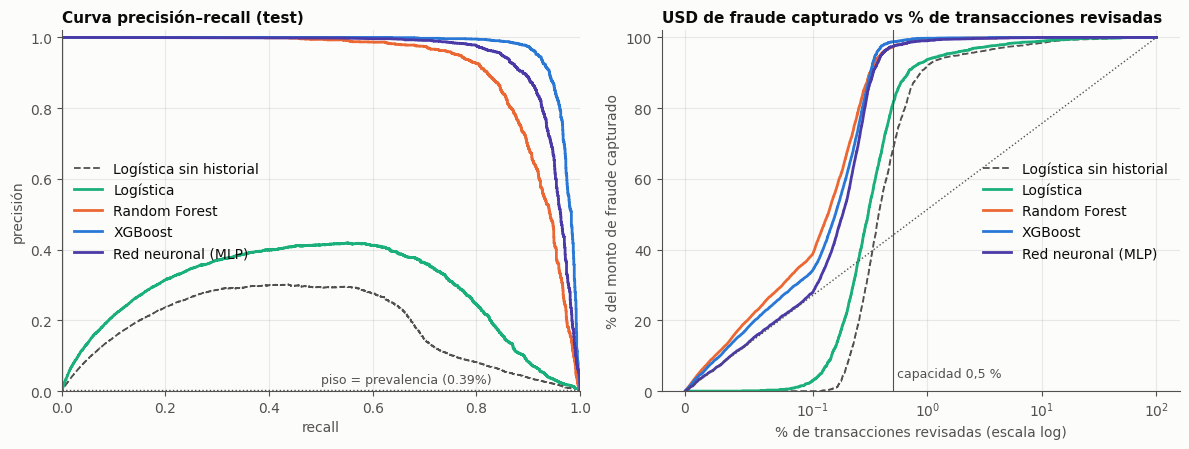

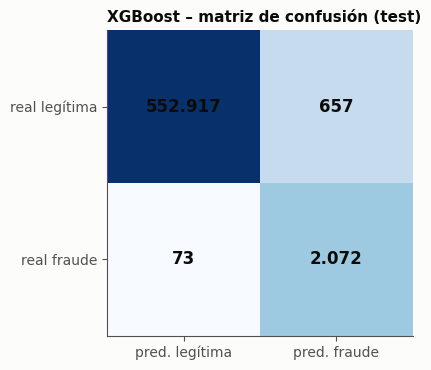

In [15]:
# Figura: curva PR y curva de ganancia (USD de fraude capturado vs % de transacciones revisadas)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
cols_ = {'Logística': AQUA, 'Random Forest': ORANGE, 'XGBoost': BLUE, 'Red neuronal (MLP)': '#4a3aa7', BASELINE_LR[0]: MUTED}
a = ax[0]
for name in [BASELINE_LR[0]] + MAIN:
    p, r, _ = precision_recall_curve(yte, s_te[name])
    a.plot(r, p, color=cols_[name], lw=2 if name != BASELINE_LR[0] else 1.3, ls='-' if name != BASELINE_LR[0] else '--', label=name)
a.axhline(prev_te, color=MUTED, lw=1, ls=':'); a.text(.5, prev_te + .02, f'piso = prevalencia ({prev_te:.2%})', color=MUTED, fontsize=9)
a.set(title='Curva precisión–recall (test)', xlabel='recall', ylabel='precisión', xlim=(0, 1), ylim=(0, 1.02)); a.legend(frameon=False, loc='center left')
a = ax[1]
for name in [BASELINE_LR[0]] + MAIN:
    o = np.argsort(-s_te[name]); gain = np.cumsum(amt_te[o] * yte[o]) / amt_te[yte == 1].sum()
    a.plot(np.arange(1, len(o) + 1) / len(o) * 100, gain * 100, color=cols_[name], lw=2 if name != BASELINE_LR[0] else 1.3,
           ls='-' if name != BASELINE_LR[0] else '--', label=name)
a.plot([0, 100], [0, 100], color=MUTED, lw=1, ls=':'); a.set_xscale('symlog', linthresh=.1)
a.axvline(CAP * 100, color=MUTED, lw=.8); a.text(CAP * 100 * 1.1, 4, 'capacidad 0,5 %', color=MUTED, fontsize=9)
a.set(title='USD de fraude capturado vs % de transacciones revisadas', xlabel='% de transacciones revisadas (escala log)',
      ylabel='% del monto de fraude capturado', ylim=(0, 102)); a.legend(frameon=False, loc='center right')
save('fig_pr_ganancia.png')

# Matriz de confusión del modelo seleccionado al umbral por costo
sel_pred = s_te[SEL] >= THR[SEL][10]
cm = np.array([[((~sel_pred) & (yte == 0)).sum(), (sel_pred & (yte == 0)).sum()], [((~sel_pred) & (yte == 1)).sum(), (sel_pred & (yte == 1)).sum()]])
pd.DataFrame(cm, index=['real legítima', 'real fraude'], columns=['pred legítima', 'pred fraude']).to_csv(RES / 'matriz_confusion.csv')
fig, a = plt.subplots(figsize=(4.8, 3.8)); a.imshow(np.log10(cm + 1), cmap='Blues'); a.grid(False)
for i in range(2):
    for j in range(2): a.text(j, i, f'{cm[i, j]:,}'.replace(',', '.'), ha='center', va='center', color=INK, fontsize=12, fontweight='bold')
a.set_xticks([0, 1]); a.set_xticklabels(['pred. legítima', 'pred. fraude']); a.set_yticks([0, 1]); a.set_yticklabels(['real legítima', 'real fraude'])
a.set_title(f'{SEL} – matriz de confusión (test)'); save('fig_confusion.png')

## 8. Impacto del drift, interpretación, valor de negocio y ética

### 8.1 Desempeño mes a mes en test (drift)

,mes,n,fraudes,prevalencia,pr_auc,pr_auc_sobre_piso,recall,precision,pct_usd_capturado,falsas_alarmas_por_dia
0,2020-06-01,30058,133,0.0044,0.9764,220.6681,0.9774,0.7647,0.9924,3.8132
1,2020-07-01,85848,321,0.0037,0.9596,256.6451,0.9533,0.7150,0.9955,3.8126
2,2020-08-01,88759,415,0.0047,0.9765,208.8604,0.9711,0.7840,0.9892,3.4688
3,2020-09-01,69533,340,0.0049,0.9739,199.1631,0.9588,0.8069,0.9756,2.5162
4,2020-10-01,69348,384,0.0055,0.9773,176.4865,0.9688,0.8035,0.9898,2.8438
5,2020-11-01,72635,294,0.0040,0.9801,242.1521,0.9830,0.7853,0.9987,2.5484
6,2020-12-01,139538,258,0.0018,0.9630,520.8117,0.9535,0.6440,0.9759,4.2501


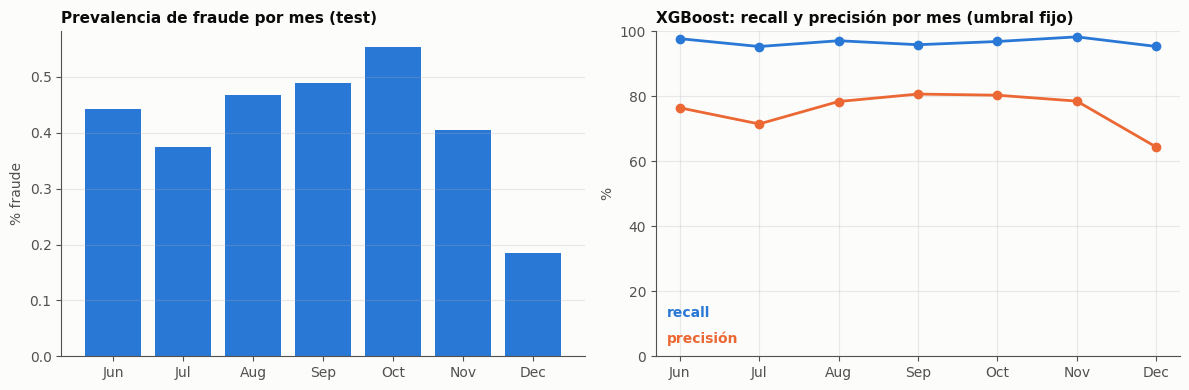

In [16]:
sc = s_te[SEL]; thr = THR[SEL][10]
dte['mes'] = dte.trans_date_trans_time.dt.to_period('M').dt.to_timestamp()
tm = []
for m_, g_ in dte.groupby('mes'):
    y_, s_, a_ = g_.is_fraud.values, sc[g_.index], g_.amt.values
    om = op_metrics(y_, s_ >= thr, a_, (g_.trans_date_trans_time.max() - g_.trans_date_trans_time.min()).total_seconds() / 86400 + 1)
    tm.append(dict(mes=m_, n=len(g_), fraudes=int(y_.sum()), prevalencia=y_.mean(), pr_auc=average_precision_score(y_, s_),
                   pr_auc_sobre_piso=average_precision_score(y_, s_) / y_.mean(), recall=om['recall'], precision=om['precision'],
                   pct_usd_capturado=om['pct_usd_capturado'], falsas_alarmas_por_dia=om['falsas_alarmas_por_dia']))
tm = pd.DataFrame(tm); tm.to_csv(RES / 'temporal_metrics.csv', index=False); display(tm.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
a = ax[0]; a.bar(tm.mes.dt.strftime('%b'), tm.prevalencia * 100, color=BLUE); a.set(title='Prevalencia de fraude por mes (test)', ylabel='% fraude'); a.grid(axis='x', visible=False)
a = ax[1]; a.plot(tm.mes.dt.strftime('%b'), tm.recall * 100, color=BLUE, lw=2, marker='o'); a.plot(tm.mes.dt.strftime('%b'), tm.precision * 100, color=ORANGE, lw=2, marker='o')
a.text(.02, .12, 'recall', color=BLUE, transform=a.transAxes, fontweight='bold'); a.text(.02, .04, 'precisión', color=ORANGE, transform=a.transAxes, fontweight='bold')
a.set(title=f'{SEL}: recall y precisión por mes (umbral fijo)', ylabel='%', ylim=(0, 100)); save('fig_temporal.png')

### 8.2 Interpretación: SHAP y ablaciones

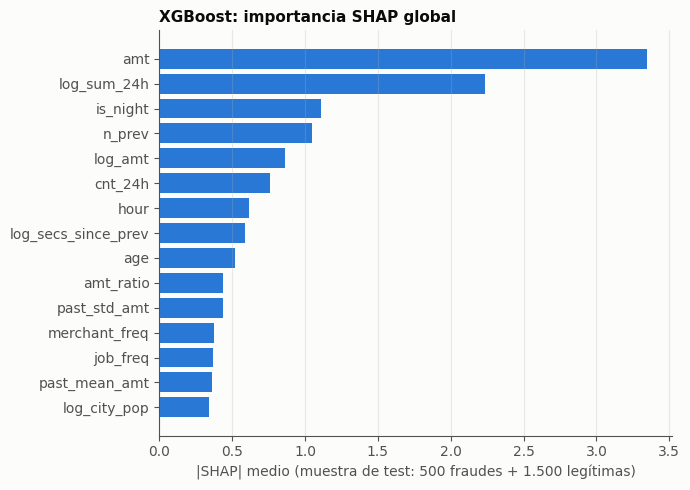

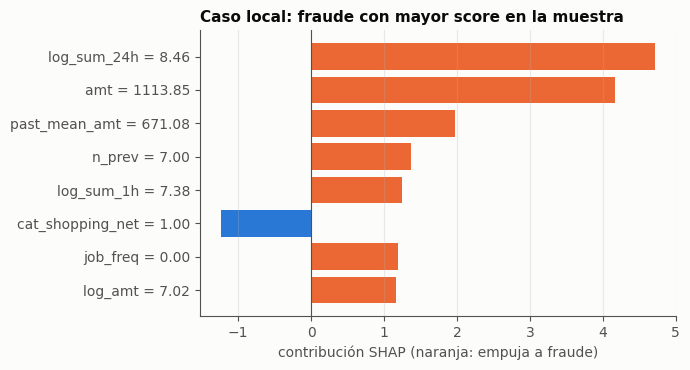

,0
amt,3.3508
log_sum_24h,2.2351
is_night,1.1084
n_prev,1.0474
log_amt,0.8616
cnt_24h,0.7599
hour,0.6174
log_secs_since_prev,0.5870
age,0.5183
amt_ratio,0.4402


In [17]:
import shap
rng = np.random.RandomState(SEED)
pos, neg = np.where(yte == 1)[0], np.where(yte == 0)[0]
samp = np.sort(np.concatenate([rng.choice(pos, 500, replace=False), rng.choice(neg, 1500, replace=False)]))
alg_sel, feats_sel = MODELS[SEL]; ci = cols(feats_sel); Xs = Xte_all[samp][:, ci]
m_sel = fitted[SEL]
assert alg_sel in ('LR', 'RF', 'XGB'), 'SHAP no implementado para el MLP'
if alg_sel == 'LR':
    Xt = m_sel.named_steps['sc'].transform(Xs); sv = shap.LinearExplainer(m_sel.named_steps['lr'], Xt).shap_values(Xt)
else:
    sv = shap.TreeExplainer(m_sel).shap_values(Xs)
    if isinstance(sv, list): sv = sv[1]
    elif np.ndim(sv) == 3: sv = sv[:, :, 1]
imp = pd.Series(np.abs(sv).mean(0), index=feats_sel).sort_values(ascending=False)
imp.to_csv(RES / 'shap_global.csv', header=['mean_abs_shap'])
top = imp.head(15)[::-1]
fig, a = plt.subplots(figsize=(7, 5)); a.barh(top.index, top.values, color=BLUE); a.grid(axis='y', visible=False)
a.set(title=f'{SEL}: importancia SHAP global', xlabel='|SHAP| medio (muestra de test: 500 fraudes + 1.500 legítimas)'); save('fig_shap_global.png')

# Caso local: el fraude de test con mayor score dentro de la muestra
loc = int(np.argmax(np.where(yte[samp] == 1, sc[samp], -1)))
contrib = pd.Series(sv[loc], index=feats_sel); vals = pd.Series(Xs[loc], index=feats_sel)
topc = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)[::-1]
loc_tab = pd.DataFrame({'shap': topc, 'valor': vals[topc.index]}); loc_tab.to_csv(RES / 'shap_local_case.csv')
fig, a = plt.subplots(figsize=(7, 3.8)); a.barh([f'{i} = {vals[i]:.2f}' for i in topc.index], topc.values, color=[ORANGE if v > 0 else BLUE for v in topc.values])
a.axvline(0, color=MUTED, lw=.8); a.grid(axis='y', visible=False); a.set(title='Caso local: fraude con mayor score en la muestra', xlabel='contribución SHAP (naranja: empuja a fraude)'); save('fig_shap_local.png')
display(imp.head(15).round(4).to_frame())

In [18]:
# Ablaciones: se reentrena el modelo seleccionado sin cada bloque de variables
ABL = {'Modelo completo': [], 'Sin historial por tarjeta (H4)': HIST, 'Sin variables temporales (H1)': TIME,
       'Sin categoría ni comercio (H2)': CATCOLS + ['merchant_freq'], 'Sin monto actual (H3)': AMTF, 'Sin distancia': GEO,
       'Sin n_prev (antigüedad de la tarjeta, no estacionaria)': ['n_prev']}
ab = []
for nombre, drop in ABL.items():
    t0 = time.time(); fs = [c for c in ALL if c not in drop]
    if not drop: s = sc
    else:
        mm = make_model(alg_sel, ytr); fit_model(alg_sel, mm, Xtr_all[:, cols(fs)], ytr); s = mm.predict_proba(Xte_all[:, cols(fs)])[:, 1]
    rc, rcu = recall_at_cap(yte, s, amt_te)
    ab.append(dict(escenario=nombre, n_variables=len(fs), pr_auc=average_precision_score(yte, s), recall_cap=rc, pct_usd_cap=rcu))
    print(f'{nombre:34s} PR-AUC {ab[-1]["pr_auc"]:.4f} ({time.time() - t0:.0f} s)')
ab = pd.DataFrame(ab); ab['delta_pr_auc'] = ab.pr_auc - ab.pr_auc.iloc[0]; ab['delta_recall_cap'] = ab.recall_cap - ab.recall_cap.iloc[0]
ab.to_csv(RES / 'ablaciones.csv', index=False); display(ab.round(4))

Modelo completo                    PR-AUC 0.9725 (0 s)


Sin historial por tarjeta (H4)     PR-AUC 0.8649 (4 s)


Sin variables temporales (H1)      PR-AUC 0.9328 (5 s)


Sin categoría ni comercio (H2)     PR-AUC 0.8784 (4 s)


Sin monto actual (H3)              PR-AUC 0.7332 (4 s)


Sin distancia                      PR-AUC 0.9745 (5 s)


Sin n_prev (antigüedad de la tarjeta, no estacionaria) PR-AUC 0.9743 (5 s)


,escenario,n_variables,pr_auc,recall_cap,pct_usd_cap,delta_pr_auc,delta_recall_cap
0,Modelo completo,36,0.9725,0.9664,0.9877,0.0000,0.0000
1,Sin historial por tarjeta (H4),25,0.8649,0.8322,0.9334,-0.1076,-0.1343
2,Sin variables temporales (H1),33,0.9328,0.9170,0.9448,-0.0397,-0.0494
3,Sin categoría ni comercio (H2),21,0.8784,0.8583,0.9485,-0.0941,-0.1082
4,Sin monto actual (H3),32,0.7332,0.7282,0.8277,-0.2393,-0.2382
5,Sin distancia,35,0.9745,0.9702,0.9872,0.0020,0.0037
6,"Sin n_prev (antigüedad de la tarjeta, no estac...",35,0.9743,0.9678,0.9887,0.0018,0.0014


### 8.3 Valor de negocio
Se compara el escenario *sin modelo* (todo el fraude se pierde), la regla de negocio y los modelos. **Supuestos:** el fraude marcado se bloquea en tiempo real y evita su monto íntegro; cada falsa alarma cuesta C USD. Los montos son del período de test (≈ 6,3 meses) y se anualizan proporcionalmente (× 365 / días de test) sin considerar crecimiento.

In [19]:
ANUAL = 365 / DAYS_TEST
def scen(nombre, m, C):
    cap, fp = m['fraude_usd_capturado'], m['fp']
    return dict(escenario=nombre, C_falsa_alarma_usd=C, fraude_total_usd=m['fraude_usd_total'], fraude_evitado_usd=cap,
                fraude_residual_usd=m['fraude_usd_total'] - cap, falsas_alarmas=fp, costo_revision_usd=C * fp,
                ahorro_neto_usd=cap - C * fp, ahorro_neto_anualizado_usd=(cap - C * fp) * ANUAL)
esc = []
for C in (5, 10, 25, 50):
    m0 = op_metrics(yte, np.zeros(len(yte)), amt_te, DAYS_TEST); esc.append(scen('Sin modelo', m0, C))
    xr = X_RULE[C]; esc.append(scen('Regla de negocio', op_metrics(yte, (dte.is_night.values == 1) & (amt_te > xr), amt_te, DAYS_TEST), C))
    for name in [BASELINE_LR[0]] + MAIN:
        esc.append(scen(name, op_metrics(yte, s_te[name] >= THR[name][C], amt_te, DAYS_TEST), C))
esc = pd.DataFrame(esc); esc.to_csv(RES / 'escenario_economico.csv', index=False)
display(esc[esc.C_falsa_alarma_usd == 10].round(0))
display(esc.pivot(index='escenario', columns='C_falsa_alarma_usd', values='ahorro_neto_usd').round(0))

,escenario,C_falsa_alarma_usd,fraude_total_usd,fraude_evitado_usd,fraude_residual_usd,falsas_alarmas,costo_revision_usd,ahorro_neto_usd,ahorro_neto_anualizado_usd
7,Sin modelo,10,1133325.0,0.0,1133325.0,0,0,0.0,0.0
8,Regla de negocio,10,1133325.0,944039.0,189286.0,3378,33780,910259.0,1717118.0
9,Logística sin historial,10,1133325.0,1073654.0,59671.0,7952,79520,994134.0,1875339.0
10,Logística,10,1133325.0,1067076.0,66249.0,4452,44520,1022556.0,1928955.0
11,Random Forest,10,1133325.0,1113627.0,19697.0,1587,15870,1097757.0,2070816.0
12,XGBoost,10,1133325.0,1119266.0,14059.0,657,6570,1112696.0,2098996.0
13,Red neuronal (MLP),10,1133325.0,1113364.0,19960.0,1384,13840,1099524.0,2074149.0


C_falsa_alarma_usd,5,10,25,50
escenario,,,,
Logística,1043394.0,1022556.0,971459.0,903383.0
Logística sin historial,1031038.0,994134.0,931997.0,836729.0
Random Forest,1110899.0,1097757.0,1082375.0,1063990.0
Red neuronal (MLP),1105549.0,1099524.0,1078467.0,1051336.0
Regla de negocio,926108.0,910259.0,864667.0,796955.0
Sin modelo,0.0,0.0,0.0,0.0
XGBoost,1115711.0,1112696.0,1102979.0,1095262.0


### 8.4 Auditoría por grupos (ética)
Se compara, para el modelo seleccionado al umbral por costo, la tasa de alertas, el recall y la tasa de falsos positivos por género y por tramo de edad. El género y la edad **sí** son variables del modelo (`gender_M`, `age`); la auditoría verifica que no genere cargas desiguales de falsas alarmas.

In [20]:
dte['pred_sel'] = (sc >= thr).astype(int)
dte['edad_tramo'] = pd.cut(dte.age, [0, 30, 45, 60, 120], right=False, labels=['<30', '30-44', '45-59', '60+'])
aud = []
for attr, col in (('género', 'gender'), ('edad', 'edad_tramo')):
    for gname, g_ in dte.groupby(col, observed=True):
        y_, p_ = g_.is_fraud.values == 1, g_.pred_sel.values == 1
        aud.append(dict(atributo=attr, grupo=str(gname), n=len(g_), fraudes=int(y_.sum()), tasa_fraude=y_.mean(), alertas_pct=p_.mean(),
                        recall=(p_ & y_).sum() / max(y_.sum(), 1), tasa_falsos_positivos=(p_ & ~y_).sum() / max((~y_).sum(), 1),
                        precision=(p_ & y_).sum() / max(p_.sum(), 1), pct_del_total_de_alertas=p_.sum() / dte.pred_sel.sum()))
aud = pd.DataFrame(aud); aud.to_csv(RES / 'auditoria_grupos.csv', index=False); display(aud.round(4))

,atributo,grupo,n,fraudes,tasa_fraude,alertas_pct,recall,tasa_falsos_positivos,precision,pct_del_total_de_alertas
0,género,F,304886,1164,0.0038,0.0050,0.9519,0.0013,0.7309,0.5555
1,género,M,250833,981,0.0039,0.0048,0.9827,0.0010,0.7947,0.4445
2,edad,<30,94017,317,0.0034,0.0046,0.9937,0.0013,0.7258,0.1590
3,edad,30-44,185867,649,0.0035,0.0047,0.9584,0.0013,0.7158,0.3184
4,edad,45-59,152764,604,0.0040,0.0050,0.9487,0.0013,0.7480,0.2807
5,edad,60+,123071,575,0.0047,0.0054,0.9774,0.0008,0.8515,0.2418


### 8.5 Resumen de cifras clave

In [21]:
mm_ = met[(met.modelo == SEL) & (met.punto_operativo == 'umbral por costo')].iloc[0]
mc_ = met[(met.modelo == SEL) & (met.punto_operativo == 'capacidad 0,5 %')].iloc[0]
mr_ = met[met.modelo.str.startswith('Regla')].iloc[0]
mb_ = met[(met.modelo == BASELINE_LR[0]) & (met.punto_operativo == 'umbral por costo')].iloc[0]
e10 = esc[esc.C_falsa_alarma_usd == 10].set_index('escenario')
res = {'modelo_seleccionado': SEL, 'prevalencia_test': prev_te, 'pr_auc_test': mm_.pr_auc, 'pr_auc_sobre_piso': mm_.pr_auc / prev_te,
       'roc_auc_test': mm_.roc_auc, 'pr_auc_baseline_logistica_sin_historial': mb_.pr_auc,
       'umbral_costo_C10': THR[SEL][10], 'recall_umbral_costo': mm_.recall, 'precision_umbral_costo': mm_.precision, 'f1_umbral_costo': mm_.f1,
       'pct_usd_capturado_umbral_costo': mm_.pct_usd_capturado, 'usd_capturado_umbral_costo': mm_.fraude_usd_capturado,
       'fraude_usd_total_test': mm_.fraude_usd_total, 'falsas_alarmas_umbral_costo': mm_.fp, 'falsas_alarmas_por_dia': mm_.falsas_alarmas_por_dia,
       'falsas_alarmas_por_1000_tx': mm_.falsas_alarmas_por_1000_tx, 'recall_capacidad_05': mc_.recall, 'pct_usd_capturado_capacidad_05': mc_.pct_usd_capturado,
       'precision_capacidad_05': mc_.precision, 'regla_pct_usd_capturado': mr_.pct_usd_capturado, 'regla_recall': mr_.recall,
       'regla_precision': mr_.precision, 'regla_falsas_alarmas_por_dia': mr_.falsas_alarmas_por_dia, 'regla_umbral_monto_usd': X_RULE[10],
       'ahorro_neto_modelo_test_usd': e10.loc[SEL, 'ahorro_neto_usd'], 'ahorro_neto_regla_test_usd': e10.loc['Regla de negocio', 'ahorro_neto_usd'],
       'ahorro_neto_modelo_anualizado_usd': e10.loc[SEL, 'ahorro_neto_anualizado_usd'], 'dias_test': DAYS_TEST}
pd.Series(res).to_csv(RES / 'resumen.csv', header=['valor']); display(pd.Series(res).to_frame('valor'))
print(f'Tiempo total de ejecución: {(time.time() - T0) / 60:.1f} min')

,valor
modelo_seleccionado,XGBoost
prevalencia_test,0.00386
pr_auc_test,0.972489
pr_auc_sobre_piso,251.949064
roc_auc_test,0.999313
pr_auc_baseline_logistica_sin_historial,0.18441
umbral_costo_C10,0.101709
recall_umbral_costo,0.965967
precision_umbral_costo,0.759252
f1_umbral_costo,0.850226


Tiempo total de ejecución: 13.3 min
